<a href="https://colab.research.google.com/github/VALTOm07/ML_Challenge02_MineriaDeAsteroides/blob/main/pipeline_razonamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline de razonamiento, búsqueda y resultados

**Caso:** minería de asteroides. Este notebook implementa un modelo conceptual de búsqueda en anchura (BFS). Los estados y las reglas son académicos; no prueban la viabilidad de una misión real.

## 1. Definición del problema

Explorar una ruta conceptual desde el inicio de la evaluación hasta un resultado preliminar. La fuente del caso no proporciona datos suficientes para decidir la rentabilidad real de una misión.

In [1]:
from collections import deque

estados = {
    'S0': 'Inicio',
    'S1': 'Tecnología revisada',
    'S2': 'Economía calculada',
    'S3': 'Restricciones revisadas',
    'S4': 'Evaluación preliminar favorable',
    'S5': 'Requiere más evidencia',
}

grafo = {
    'S0': ['S1'],
    'S1': ['S2'],
    'S2': ['S3'],
    'S3': ['S4', 'S5'],
    'S4': [],
    'S5': [],
}
print('Estados:', estados)

Estados: {'S0': 'Inicio', 'S1': 'Tecnología revisada', 'S2': 'Economía calculada', 'S3': 'Restricciones revisadas', 'S4': 'Evaluación preliminar favorable', 'S5': 'Requiere más evidencia'}


## 2. Espacio de estados y restricciones

- **Estados:** S0–S5.
- **Operadores:** revisar tecnología, calcular economía, revisar restricciones y clasificar.
- **Restricciones:** los umbrales son hipotéticos y deben identificarse como tales.
- **Transiciones:** definidas en el diccionario `grafo`.

In [2]:
def busqueda_anchura(inicio, objetivo, grafo):
    """BFS: retorna estados visitados y camino al objetivo, si existe."""
    cola = deque([inicio])
    padre = {inicio: None}
    visitados = []

    while cola:
        actual = cola.popleft()
        visitados.append(actual)
        if actual == objetivo:
            break
        for vecino in grafo.get(actual, []):
            if vecino not in padre:
                padre[vecino] = actual
                cola.append(vecino)

    camino = []
    if objetivo in padre:
        actual = objetivo
        while actual is not None:
            camino.append(actual)
            actual = padre[actual]
        camino.reverse()
    return visitados, camino

objetivo = 'S4'
visitados, camino = busqueda_anchura('S0', objetivo, grafo)
print('Orden de visita:', visitados)
print('Camino encontrado:', camino)
print('Interpretación:', ' -> '.join(estados[s] for s in camino) if camino else 'No se encontró ruta')

Orden de visita: ['S0', 'S1', 'S2', 'S3', 'S4']
Camino encontrado: ['S0', 'S1', 'S2', 'S3', 'S4']
Interpretación: Inicio -> Tecnología revisada -> Economía calculada -> Restricciones revisadas -> Evaluación preliminar favorable


## 3. Visualización del grafo

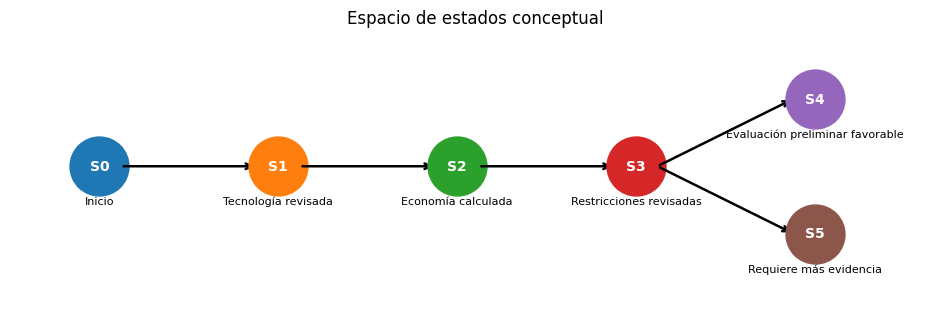

In [3]:
import matplotlib.pyplot as plt

pos = {'S0': (0, 0), 'S1': (1, 0), 'S2': (2, 0), 'S3': (3, 0), 'S4': (4, 0.5), 'S5': (4, -0.5)}
fig, ax = plt.subplots(figsize=(12, 3.5))
for origen, destinos in grafo.items():
    x1, y1 = pos[origen]
    ax.scatter(x1, y1, s=1800, zorder=3)
    ax.text(x1, y1, origen, ha='center', va='center', color='white', weight='bold')
    for destino in destinos:
        x2, y2 = pos[destino]
        ax.annotate('', xy=(x2-.12, y2), xytext=(x1+.12, y1), arrowprops=dict(arrowstyle='->', lw=1.8))
for s, (x, y) in pos.items():
    ax.text(x, y-.22, estados[s], ha='center', va='top', fontsize=8)
ax.set_xlim(-.5, 4.7); ax.set_ylim(-1, 1); ax.axis('off')
ax.set_title('Espacio de estados conceptual')
plt.show()

## 4. Resultado y límites

BFS encuentra una ruta según las transiciones definidas. No compara la calidad económica de distintas misiones ni utiliza datos operativos reales. La conclusión responsable es que la información disponible no demuestra la viabilidad económica de una misión; tampoco demuestra su inviabilidad.